# Notebook 06 — Multiclass Classification and Model Evaluation

**Level:** Beginner to Intermediate  
**Track:** Deep Learning with TensorFlow  
**Main tools:** TensorFlow, Keras, NumPy, Pandas, Matplotlib, and scikit-learn  
**Problem type:** Single-label multiclass classification

This notebook extends binary classification to problems with three or more mutually exclusive classes. It covers label encoding, softmax probabilities, categorical cross-entropy, class imbalance, multiclass evaluation metrics, and error analysis. A complete neural-network workflow is built and compared with simple baselines.

> **Important:** The dataset in this notebook is synthetic and is used only for learning. The generated classes do not represent real diseases, biological subtypes, or clinical outcomes. Model performance on synthetic data does not establish real-world or clinical validity.

## Learning Objectives

By the end of this notebook, you should be able to:

1. Distinguish binary, single-label multiclass, and multilabel classification.
2. Explain how a softmax layer converts logits into a probability distribution.
3. Represent class labels using integer encoding and one-hot encoding.
4. Select between sparse and non-sparse categorical cross-entropy.
5. Build and train a multiclass MLP with the Keras API.
6. Explain why stratified splitting and training-only preprocessing are important.
7. Interpret a multiclass confusion matrix and per-class precision, recall, and F1-score.
8. Compare micro, macro, and weighted averaging.
9. Evaluate multiclass probability scores using one-vs-rest ROC-AUC and average precision.
10. Investigate class imbalance and compare unweighted with class-weighted training.
11. Perform error analysis without using the test set for model selection.

## Notebook Roadmap

| Section | Topic |
|---:|---|
| 1 | Classification problem types and multiclass outputs |
| 2 | Softmax, logits, and probability interpretation |
| 3 | Integer encoding, one-hot encoding, and categorical cross-entropy |
| 4 | Create and explore an imbalanced synthetic dataset |
| 5 | Stratified splitting and leakage-safe preprocessing |
| 6 | Baseline classifiers |
| 7 | Build a multiclass neural network with Keras |
| 8 | Train unweighted and class-weighted models |
| 9 | Select a model using validation data |
| 10 | Confusion matrix and per-class metrics |
| 11 | Micro, macro, and weighted averaging |
| 12 | Multiclass ROC and precision–recall analysis |
| 13 | Model comparison and error analysis |
| 14 | Common pitfalls, exercises, and references |

Run the notebook from top to bottom. The test set is reserved for final evaluation and must not be used to choose model architecture, class weights, hyperparameters, or decision rules.

## 0. Environment Setup and Reproducibility

The examples use the TensorFlow/Keras workflow introduced in the previous notebooks. The requirements file pins a stable TensorFlow/Keras combination and lists the supporting scientific Python packages.

For reproducibility, random seeds are set where supported. Exact bitwise reproducibility is not guaranteed across all hardware, libraries, and execution environments.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Keras:", getattr(tf.keras, "__version__", "Bundled with TensorFlow"))
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
Keras: 3.15.1
NumPy: 2.4.6


## 1. Classification Problem Types

### 1.1 Binary, Single-Label Multiclass, and Multilabel Classification

Classification problems differ in how many labels may be assigned to one observation.

| Problem type | Labels per observation | Example output representation |
|---|---:|---|
| Binary classification | Exactly one of two classes | `0` or `1` |
| Single-label multiclass | Exactly one of three or more classes | One integer from `0` to `C - 1` |
| Multilabel classification | Zero, one, or several labels may be active | A vector of independent binary indicators |

This notebook focuses on **single-label multiclass classification**. Each observation belongs to exactly one of $C$ mutually exclusive classes.

Let $\mathbf{x}_i$ denote the feature vector for observation $i$, and let $y_i$ be its class index:

$$
y_i \in \{0,1,\ldots,C-1\}
$$

A model produces a score for every class. The predicted class is commonly the index with the largest predicted probability:

$$
\hat{y}_i = \operatorname*{arg\,max}_{c \in \{0,\ldots,C-1\}} \hat{p}_{ic}
$$

In contrast, a multilabel classifier often uses one sigmoid output per label because multiple labels can be simultaneously active. Softmax is appropriate when the classes are mutually exclusive and the outputs should form one probability distribution.

### 1.2 Output Dimensions

For a batch of $N$ observations and $C$ classes, the final layer of a multiclass neural network typically has $C$ units. Its output has shape $(N,C)$.

Integer-encoded targets have shape $(N,)$, while one-hot targets have shape $(N,C)$. The choice of loss function must match the target representation.

In [2]:
example_integer_labels = np.array([0, 2, 1, 0, 2])
example_one_hot_labels = np.eye(3, dtype=int)[example_integer_labels]

print("Integer labels:", example_integer_labels)
print("Integer-label shape:", example_integer_labels.shape)
print("\nOne-hot labels:\n", example_one_hot_labels)
print("One-hot shape:", example_one_hot_labels.shape)

Integer labels: [0 2 1 0 2]
Integer-label shape: (5,)

One-hot labels:
 [[1 0 0]
 [0 0 1]
 [0 1 0]
 [1 0 0]
 [0 0 1]]
One-hot shape: (5, 3)


## 2. Softmax, Logits, and Probabilities

### 2.1 Why Use Softmax?

The final Dense layer can produce one unrestricted real-valued score, called a **logit**, for each class. Softmax transforms these logits into non-negative values that sum to one across classes.

For a logit vector $\mathbf{z} = (z_1,\ldots,z_C)$, softmax is:

$$
\operatorname{softmax}(z_c) = \frac{e^{z_c}}{\sum_{j=1}^{C} e^{z_j}}
$$

The resulting values can be interpreted as the model's estimated class probabilities. They are conditional on the model and data; softmax output alone does not guarantee that the probabilities are well calibrated.

For numerical stability, implementations commonly subtract the largest logit before exponentiation. This does not change the resulting probabilities.

In [3]:
def softmax_numpy(logits):
    """Compute softmax probabilities along the final axis."""
    logits = np.asarray(logits, dtype=float)
    shifted = logits - np.max(logits, axis=-1, keepdims=True)
    exp_values = np.exp(shifted)
    return exp_values / np.sum(exp_values, axis=-1, keepdims=True)

example_logits = np.array([
    [2.0, 1.0, 0.1],
    [0.2, 0.3, 1.4],
    [3.0, 3.0, 3.0],
])
example_probabilities = softmax_numpy(example_logits)

print("Logits:\n", example_logits)
print("\nSoftmax probabilities:\n", np.round(example_probabilities, 4))
print("\nRow sums:", np.round(example_probabilities.sum(axis=1), 6))
print("Predicted classes:", np.argmax(example_probabilities, axis=1))

Logits:
 [[2.  1.  0.1]
 [0.2 0.3 1.4]
 [3.  3.  3. ]]

Softmax probabilities:
 [[0.659  0.2424 0.0986]
 [0.1843 0.2037 0.612 ]
 [0.3333 0.3333 0.3333]]

Row sums: [1. 1. 1.]
Predicted classes: [0 2 0]


### 2.2 Interpreting the Output

For each observation:

- The largest softmax value determines the predicted class under the usual `argmax` rule.
- The values across classes sum to one.
- A small gap between the largest and second-largest values indicates that the model assigns similar scores to competing classes.
- A large maximum probability should not automatically be interpreted as certainty or proof of calibration.

The conventional multiclass decision rule is:

$$
\hat{y}_i = \operatorname*{arg\,max}_c \hat{p}_{ic}
$$

There is no single binary threshold such as $0.5$ in the usual multiclass `argmax` rule. More specialized decision policies can be designed, but they should be justified by the task and selected without tuning on the test set.

In [4]:
for row_index, row in enumerate(example_probabilities):
    ranking = np.argsort(row)[::-1]
    top_class = ranking[0]
    second_class = ranking[1]
    margin = row[top_class] - row[second_class]
    print(
        f"Observation {row_index}: predicted class={top_class}, "
        f"top probability={row[top_class]:.3f}, margin={margin:.3f}"
    )

Observation 0: predicted class=0, top probability=0.659, margin=0.417
Observation 1: predicted class=2, top probability=0.612, margin=0.408
Observation 2: predicted class=2, top probability=0.333, margin=0.000


## 3. Label Encoding and Categorical Cross-Entropy

### 3.1 Integer Encoding

Integer encoding represents the correct class using one integer from $0$ to $C-1$. For example, the class sequence `A, C, B, A` can be encoded as `0, 2, 1, 0`.

Integer values here are **class identifiers**, not measurements. Class `2` is not necessarily greater than class `1` in a meaningful quantitative sense.

### 3.2 One-Hot Encoding

One-hot encoding represents each class as a vector with one active entry. For $C=3$:

$$
0 \rightarrow [1,0,0],\qquad
1 \rightarrow [0,1,0],\qquad
2 \rightarrow [0,0,1]
$$

The class order must remain consistent between the target encoding and the columns of the model output.

In [5]:
integer_labels = np.array([0, 2, 1, 0])
one_hot_labels = tf.keras.utils.to_categorical(integer_labels, num_classes=3)

print("Integer labels:", integer_labels)
print("One-hot labels:\n", one_hot_labels.astype(int))

Integer labels: [0 2 1 0]
One-hot labels:
 [[1 0 0]
 [0 0 1]
 [0 1 0]
 [1 0 0]]


### 3.3 Categorical Cross-Entropy

For one observation with one-hot target vector $\mathbf{y}$ and predicted probability vector $\hat{\mathbf{p}}$, categorical cross-entropy is:

$$
\mathcal{L}_{\mathrm{CCE}}(\mathbf{y},\hat{\mathbf{p}})
= -\sum_{c=1}^{C} y_c \log(\hat{p}_c)
$$

Because exactly one target entry is one, the loss is the negative logarithm of the probability assigned to the correct class.

For integer-encoded labels, **sparse categorical cross-entropy** expresses the same objective without requiring one-hot target vectors:

$$
\mathcal{L}_{\mathrm{SCCE}}(y,\hat{\mathbf{p}})
= -\log(\hat{p}_{y})
$$

Use:

- `SparseCategoricalCrossentropy` when the targets are integer class IDs.
- `CategoricalCrossentropy` when the targets are one-hot vectors.

The `from_logits` option must match the model output. If the model's final layer uses softmax, use `from_logits=False`. If the model returns raw logits, use `from_logits=True` and do not add a softmax activation to the final layer.

In [6]:
# A hand-worked example: compare the probability assigned to the true class.
true_class = 2
probability_vector = np.array([0.10, 0.25, 0.65])
manual_sparse_loss = -np.log(probability_vector[true_class])

one_hot_target = np.eye(3)[true_class]
manual_categorical_loss = -np.sum(one_hot_target * np.log(probability_vector))

print(f"Sparse-form loss: {manual_sparse_loss:.6f}")
print(f"One-hot-form loss: {manual_categorical_loss:.6f}")

Sparse-form loss: 0.430783
One-hot-form loss: 0.430783


In [7]:
# Verify that the two Keras loss formulations agree for equivalent targets.
probability_tensor = tf.constant([[0.70, 0.20, 0.10], [0.10, 0.25, 0.65]], dtype=tf.float32)
integer_target_tensor = tf.constant([0, 2], dtype=tf.int32)
one_hot_target_tensor = tf.one_hot(integer_target_tensor, depth=3)

sparse_loss = tf.keras.losses.SparseCategoricalCrossentropy()(integer_target_tensor, probability_tensor)
categorical_loss = tf.keras.losses.CategoricalCrossentropy()(one_hot_target_tensor, probability_tensor)

print("Sparse categorical cross-entropy:", float(sparse_loss.numpy()))
print("Categorical cross-entropy:", float(categorical_loss.numpy()))
print("Absolute difference:", float(tf.abs(sparse_loss - categorical_loss).numpy()))

Sparse categorical cross-entropy: 0.39372897148132324
Categorical cross-entropy: 0.39372897148132324
Absolute difference: 0.0


### 3.4 Why Confident Mistakes Are Penalized

If the true class receives a probability close to one, the loss is small. If the model assigns a probability close to zero to the true class, the loss becomes large.

For a target class $y$, the loss is $-\log(\hat{p}_y)$. The following plot illustrates this relationship.

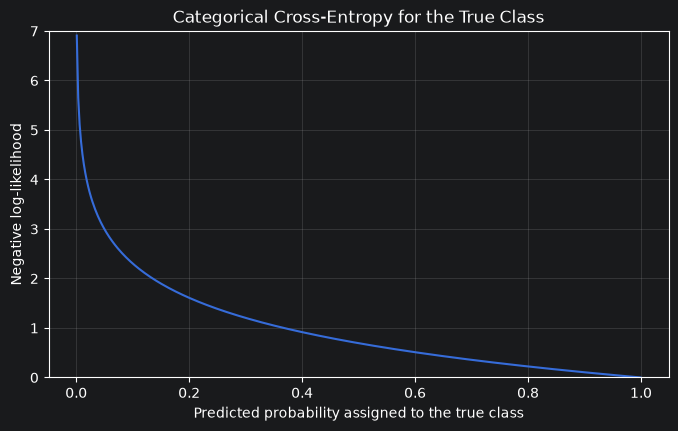

In [8]:
correct_class_probability = np.linspace(0.001, 0.999, 400)
negative_log_likelihood = -np.log(correct_class_probability)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(correct_class_probability, negative_log_likelihood)
ax.set(
    title="Categorical Cross-Entropy for the True Class",
    xlabel="Predicted probability assigned to the true class",
    ylabel="Negative log-likelihood",
)
ax.set_ylim(0, 7)
ax.grid(alpha=0.25)
plt.show()

## 4. Create and Explore a Multiclass Dataset

### 4.1 Synthetic Dataset Design

We will generate a three-class dataset with an intentionally imbalanced class distribution. The features are continuous and have no clinical or biological interpretation. They are named generically to avoid implying that they represent measured biomarkers.

A synthetic dataset is useful here because it allows us to control the number of classes, feature dimensions, noise, and class proportions without downloading external files.

In [9]:
N_SAMPLES = 3000
N_FEATURES = 14
N_CLASSES = 3
CLASS_NAMES = np.array(["Class A", "Class B", "Class C"])
FEATURE_NAMES = [f"feature_{i:02d}" for i in range(1, N_FEATURES + 1)]

X, y = make_classification(
    n_samples=N_SAMPLES,
    n_features=N_FEATURES,
    n_informative=8,
    n_redundant=2,
    n_repeated=0,
    n_classes=N_CLASSES,
    n_clusters_per_class=2,
    weights=[0.68, 0.22, 0.10],
    class_sep=1.0,
    flip_y=0.025,
    random_state=SEED,
)

X = X.astype(np.float32)
y = y.astype(np.int32)

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Observed class IDs:", np.unique(y))

Feature matrix shape: (3000, 14)
Target vector shape: (3000,)
Observed class IDs: [0 1 2]


### 4.2 Inspect the Class Distribution

Class imbalance occurs when some classes have substantially fewer observations than others. A classifier can achieve high accuracy by performing well on the majority class while performing poorly on a minority class.

,class_id,class_name,count,proportion
0,0,Class A,2018,0.672667
1,1,Class B,664,0.221333
2,2,Class C,318,0.106000


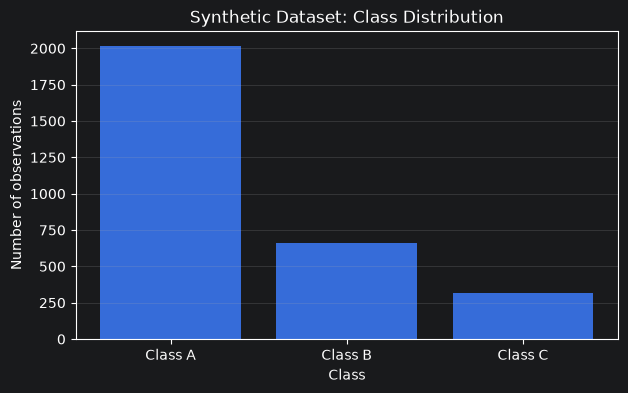

In [10]:
class_counts = pd.Series(y).value_counts().sort_index()
class_distribution = pd.DataFrame({
    "class_id": class_counts.index,
    "class_name": CLASS_NAMES[class_counts.index],
    "count": class_counts.values,
    "proportion": class_counts.values / len(y),
})

display(class_distribution)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(class_distribution["class_name"], class_distribution["count"])
ax.set(title="Synthetic Dataset: Class Distribution", xlabel="Class", ylabel="Number of observations")
ax.grid(axis="y", alpha=0.25)
plt.show()

### 4.3 Feature Inspection

A simple two-dimensional projection can help visualize whether classes overlap. Principal component analysis (PCA) is fitted here only for exploratory visualization. It is not used as a preprocessing step for the model.

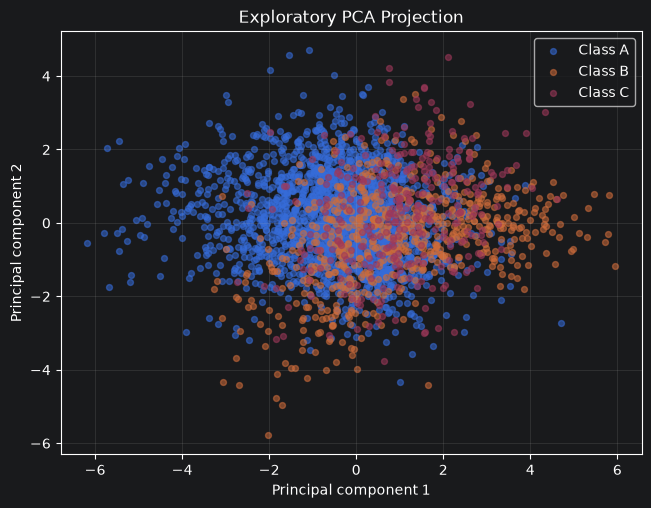

In [11]:
from sklearn.decomposition import PCA

X_for_pca = StandardScaler().fit_transform(X)
X_pca = PCA(n_components=2, random_state=SEED).fit_transform(X_for_pca)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for class_id, class_name in enumerate(CLASS_NAMES):
    mask = y == class_id
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=18, alpha=0.55, label=class_name)
ax.set(title="Exploratory PCA Projection", xlabel="Principal component 1", ylabel="Principal component 2")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## 5. Stratified Splitting and Leakage-Safe Preprocessing

### 5.1 Train, Validation, and Test Sets

We create three mutually exclusive subsets:

- **Training set:** used to fit model parameters.
- **Validation set:** used for model selection, early stopping, and comparing training strategies.
- **Test set:** used once for final evaluation after decisions have been made.

Stratification aims to preserve class proportions across the subsets. This is especially important when the least common class has relatively few observations.

In [12]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    stratify=y,
    random_state=SEED,
)

validation_fraction_of_train_val = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=validation_fraction_of_train_val,
    stratify=y_train_val,
    random_state=SEED,
)

print(f"Train:      {len(y_train):4d} ({len(y_train) / len(y):.1%})")
print(f"Validation: {len(y_val):4d} ({len(y_val) / len(y):.1%})")
print(f"Test:       {len(y_test):4d} ({len(y_test) / len(y):.1%})")

Train:      2099 (70.0%)
Validation:  451 (15.0%)
Test:        450 (15.0%)


In [13]:
def show_class_distribution(name, labels):
    counts = np.bincount(labels, minlength=N_CLASSES)
    proportions = counts / counts.sum()
    return pd.DataFrame({
        "split": name,
        "class": CLASS_NAMES,
        "count": counts,
        "proportion": proportions,
    })

split_distribution = pd.concat([
    show_class_distribution("Train", y_train),
    show_class_distribution("Validation", y_val),
    show_class_distribution("Test", y_test),
], ignore_index=True)

display(split_distribution.pivot(index="class", columns="split", values="proportion").round(3))

split,Test,Train,Validation
class,,,
Class A,0.673,0.673,0.672
Class B,0.220,0.222,0.222
Class C,0.107,0.106,0.106


### 5.2 Fit the Scaler on Training Data Only

Feature scaling can improve neural-network optimization when input variables have different ranges. The scaler must be fitted using training observations only. Fitting it on the full dataset would allow information from the validation and test distributions to influence preprocessing.

$$
z = \frac{x - \mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}}
$$

The training-set mean and standard deviation are then applied unchanged to validation and test observations.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

print("Training mean (first 5 features):", np.round(X_train_scaled.mean(axis=0)[:5], 3))
print("Training std  (first 5 features):", np.round(X_train_scaled.std(axis=0)[:5], 3))
print("Validation shape:", X_val_scaled.shape)
print("Test shape:", X_test_scaled.shape)

Training mean (first 5 features): [-0.  0. -0. -0. -0.]
Training std  (first 5 features): [1. 1. 1. 1. 1.]
Validation shape: (451, 14)
Test shape: (450, 14)


### 5.3 Data Leakage Checklist

Before training, verify that:

1. The test set was separated before fitting preprocessing transformations.
2. The scaler was fitted using only the training set.
3. Class weights were calculated from training labels only.
4. Validation data are used for early stopping and model selection.
5. The test set is not used to choose the model, threshold, or class-weight strategy.

If resampling is used in a later project, it must be applied to training data only. Validation and test sets should retain the distribution that represents the intended evaluation setting.

## 6. Baseline Classifiers

A neural network should not be evaluated in isolation. Baseline models help answer whether the additional model complexity provides a useful improvement.

We will compare:

- **Dummy classifier:** predicts the most frequent class and provides a minimal reference.
- **Multinomial logistic regression:** a linear probabilistic classifier that is a stronger baseline.

Both models are trained using the training set. Their performance on the validation set can provide context before the neural network is selected.

In [15]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train_scaled, y_train)

dummy_val_pred = dummy_model.predict(X_val_scaled)

logistic_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED,
)
logistic_model.fit(X_train_scaled, y_train)
logistic_val_pred = logistic_model.predict(X_val_scaled)

baseline_validation = pd.DataFrame([
    {
        "model": "Majority-class dummy",
        "accuracy": accuracy_score(y_val, dummy_val_pred),
        "balanced_accuracy": balanced_accuracy_score(y_val, dummy_val_pred),
        "macro_f1": f1_score(y_val, dummy_val_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_val, dummy_val_pred, average="weighted", zero_division=0),
    },
    {
        "model": "Balanced multinomial logistic regression",
        "accuracy": accuracy_score(y_val, logistic_val_pred),
        "balanced_accuracy": balanced_accuracy_score(y_val, logistic_val_pred),
        "macro_f1": f1_score(y_val, logistic_val_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_val, logistic_val_pred, average="weighted", zero_division=0),
    },
]).set_index("model")

display(baseline_validation.round(4))

,accuracy,balanced_accuracy,macro_f1,weighted_f1
model,,,,
Majority-class dummy,0.6718,0.3333,0.2679,0.5400
Balanced multinomial logistic regression,0.6940,0.6640,0.6075,0.7165


### 6.1 Why Accuracy Is Not Enough

Accuracy is the fraction of all predictions that are correct. In an imbalanced dataset, it can be dominated by the majority class.

Balanced accuracy is the unweighted mean of class-wise recall. It gives each class equal importance, regardless of its frequency:

$$
\text{Balanced Accuracy} = \frac{1}{C}\sum_{c=1}^{C}\text{Recall}_c
$$

Macro-F1 also weights classes equally, but it incorporates both precision and recall. No single metric is best for every problem; metric selection should reflect the consequences of different classification errors.

## 7. Build a Multiclass Neural Network with Keras

### 7.1 MLP Architecture

The model uses:

- An input layer with one value per feature.
- Two hidden Dense layers with ReLU activation.
- Dropout for regularization.
- A final Dense layer with one softmax output per class.

The final layer has $C$ outputs because the task contains $C$ mutually exclusive classes.

In [16]:
INPUT_DIM = X_train_scaled.shape[1]
BATCH_SIZE = 32
EPOCHS = 80


def build_multiclass_mlp(input_dim, n_classes, seed=SEED):
    """Create a compact MLP for single-label multiclass classification."""
    tf.keras.utils.set_random_seed(seed)

    inputs = tf.keras.Input(shape=(input_dim,), name="features")
    x = tf.keras.layers.Dense(64, activation="relu", name="hidden_1")(inputs)
    x = tf.keras.layers.Dropout(0.20, name="dropout_1")(x)
    x = tf.keras.layers.Dense(32, activation="relu", name="hidden_2")(x)
    outputs = tf.keras.layers.Dense(n_classes, activation="softmax", name="class_probabilities")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="multiclass_mlp")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    return model


model_unweighted = build_multiclass_mlp(INPUT_DIM, N_CLASSES, seed=SEED)
model_unweighted.summary()

Model: "multiclass_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 14)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 64)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,139 (12.26 KB)

 Trainable params: 3,139 (12.26 KB)

 Non-trainable params: 0 (0.00 B)

### 7.2 Verify Output and Loss Shapes

Before training, inspect the output shape and verify that each row forms a probability distribution. This catches common mistakes such as using the wrong output dimension or applying a loss function that does not match the target encoding.

In [17]:
small_batch = tf.convert_to_tensor(X_train_scaled[:5])
small_probabilities = model_unweighted(small_batch, training=False).numpy()

print("Output shape:", small_probabilities.shape)
print("Row sums:", np.round(small_probabilities.sum(axis=1), 6))
print("Predicted class IDs:", np.argmax(small_probabilities, axis=1))

Output shape: (5, 3)
Row sums: [1. 1. 1. 1. 1.]
Predicted class IDs: [1 1 1 1 2]


### 7.3 Sparse versus One-Hot Loss in a Model

This notebook trains the main model using integer-encoded labels and `SparseCategoricalCrossentropy`. If one-hot labels are preferred, convert the training and validation targets using `tf.keras.utils.to_categorical` and use `CategoricalCrossentropy` instead. Do not pass one-hot targets to sparse categorical cross-entropy or integer class IDs to categorical cross-entropy.

In [18]:
# Alternative setup for one-hot targets. This is shown for learning; the main model uses sparse labels.
y_train_one_hot = tf.keras.utils.to_categorical(y_train, num_classes=N_CLASSES)
y_val_one_hot = tf.keras.utils.to_categorical(y_val, num_classes=N_CLASSES)

one_hot_loss = tf.keras.losses.CategoricalCrossentropy(from_logits=False)
sparse_loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)

print("Integer target shape:", y_train.shape)
print("One-hot target shape:", y_train_one_hot.shape)
print("One-hot target example:", y_train_one_hot[0])

Integer target shape: (2099,)
One-hot target shape: (2099, 3)
One-hot target example: [1. 0. 0.]


## 8. Train Unweighted and Class-Weighted Models

### 8.1 Early Stopping

Early stopping monitors validation loss and stops training when it no longer improves. Restoring the best weights avoids keeping parameters from a later epoch that performed worse on validation data.

In [19]:
def make_early_stopping():
    return tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        min_delta=1e-4,
    )


history_unweighted = model_unweighted.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[make_early_stopping()],
    verbose=1,
)

Epoch 1/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.6131 - loss: 0.8856 - val_accuracy: 0.7361 - val_loss: 0.6779
Epoch 2/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7718 - loss: 0.6237 - val_accuracy: 0.7827 - val_loss: 0.5649
Epoch 3/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7928 - loss: 0.5490 - val_accuracy: 0.8049 - val_loss: 0.5107
Epoch 4/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.8123 - loss: 0.5051 - val_accuracy: 0.8271 - val_loss: 0.4791
Epoch 5/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8280 - loss: 0.4621 - val_accuracy: 0.8470 - val_loss: 0.4557
Epoch 6/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8375 - loss: 0.4399 - val_accuracy: 0.8581 - val_loss: 0.4422
Epoch 7/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8428 - loss: 0.4211 - val_accuracy: 0.8714 - val_loss: 0.4265
Epoch 8/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8509 - loss: 0.3964 - val_accuracy: 0.8670 - val_lo

### 8.2 Inspect the Learning Curves

The training curve shows how well the model fits the training data. The validation curve provides an estimate of performance on observations not used to update the model weights. A widening gap can be a sign of overfitting, although learning curves should be interpreted together with final evaluation and data context.

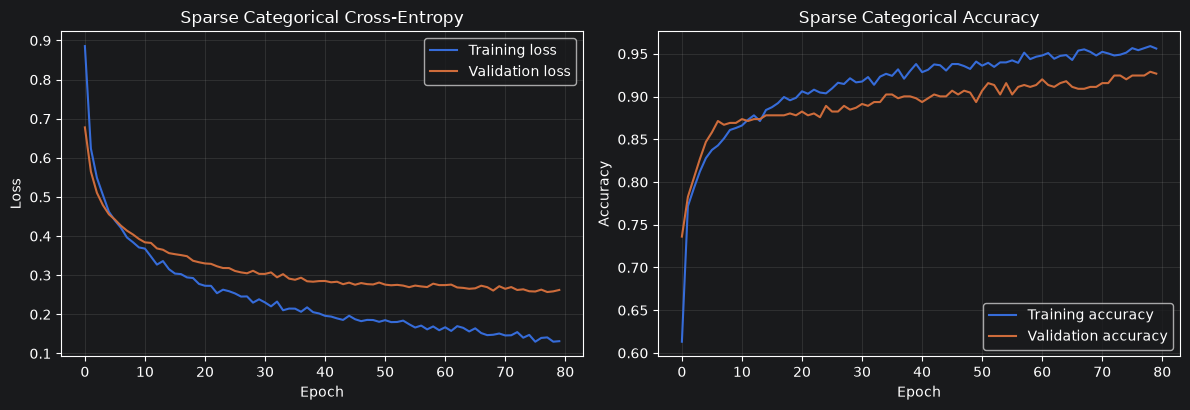

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].plot(history_unweighted.history["loss"], label="Training loss")
axes[0].plot(history_unweighted.history["val_loss"], label="Validation loss")
axes[0].set(title="Sparse Categorical Cross-Entropy", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(history_unweighted.history["accuracy"], label="Training accuracy")
axes[1].plot(history_unweighted.history["val_accuracy"], label="Validation accuracy")
axes[1].set(title="Sparse Categorical Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 8.3 Class Weights for Imbalanced Data

Class weighting increases the contribution of under-represented classes to the training loss. A commonly used balanced heuristic is:

$$
w_c = \frac{N}{C\,N_c}
$$

where $N$ is the number of training observations, $C$ is the number of classes, and $N_c$ is the number of training observations in class $c$.

The weights must be calculated from the training labels only. Class weighting changes the training objective; it does not change the class distribution of the validation or test set.

In [21]:
training_classes = np.unique(y_train)
class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=training_classes,
    y=y_train,
)
class_weight_dict = {
    int(class_id): float(weight)
    for class_id, weight in zip(training_classes, class_weight_values)
}

class_weight_table = pd.DataFrame({
    "class_id": training_classes,
    "class_name": CLASS_NAMES[training_classes],
    "training_count": np.bincount(y_train, minlength=N_CLASSES)[training_classes],
    "class_weight": class_weight_values,
})

display(class_weight_table.round(4))

,class_id,class_name,training_count,class_weight
0,0,Class A,1412,0.4955
1,1,Class B,465,1.5047
2,2,Class C,222,3.1517


### 8.4 Train the Class-Weighted Model

The model architecture and optimizer are kept the same so that this experiment focuses on the effect of class weighting. The weighted model is trained using the same training and validation subsets.

In [22]:
model_weighted = build_multiclass_mlp(INPUT_DIM, N_CLASSES, seed=SEED + 1)

history_weighted = model_weighted.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=[make_early_stopping()],
    verbose=1,
)

Epoch 1/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5317 - loss: 1.0092 - val_accuracy: 0.6386 - val_loss: 0.8609
Epoch 2/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6379 - loss: 0.8036 - val_accuracy: 0.6807 - val_loss: 0.7397
Epoch 3/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6808 - loss: 0.7094 - val_accuracy: 0.7406 - val_loss: 0.6563
Epoch 4/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7027 - loss: 0.6707 - val_accuracy: 0.7605 - val_loss: 0.6166
Epoch 5/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7375 - loss: 0.6302 - val_accuracy: 0.7627 - val_loss: 0.5974
Epoch 6/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7646 - loss: 0.5860 - val_accuracy: 0.7894 - val_loss: 0.5609
Epoch 7/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7804 - loss: 0.5716 - val_accuracy: 0.8115 - val_loss: 0.5361
Epoch 8/80
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7770 - loss: 0.5584 - val_accuracy: 0.7938 - val_loss:

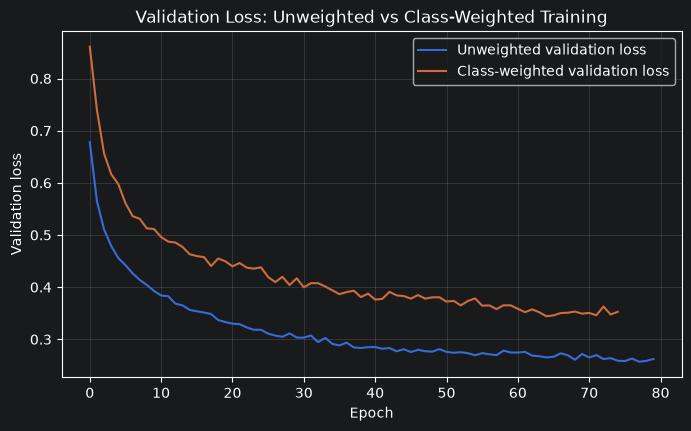

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(history_unweighted.history["val_loss"], label="Unweighted validation loss")
ax.plot(history_weighted.history["val_loss"], label="Class-weighted validation loss")
ax.set(title="Validation Loss: Unweighted vs Class-Weighted Training", xlabel="Epoch", ylabel="Validation loss")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 9. Select the Model Using Validation Data

The choice between the unweighted and class-weighted models will be based on **validation macro-F1**. Macro-F1 gives each class equal weight and can reveal whether performance on less frequent classes has improved.

The test set is not used in this selection step. After the model is selected, its test predictions are generated once for final evaluation.

In [24]:
val_prob_unweighted = model_unweighted.predict(X_val_scaled, verbose=0)
val_prob_weighted = model_weighted.predict(X_val_scaled, verbose=0)
val_pred_unweighted = np.argmax(val_prob_unweighted, axis=1)
val_pred_weighted = np.argmax(val_prob_weighted, axis=1)

val_macro_f1_unweighted = f1_score(y_val, val_pred_unweighted, average="macro", zero_division=0)
val_macro_f1_weighted = f1_score(y_val, val_pred_weighted, average="macro", zero_division=0)

validation_model_comparison = pd.DataFrame([
    {"model": "Unweighted MLP", "validation_macro_f1": val_macro_f1_unweighted},
    {"model": "Class-weighted MLP", "validation_macro_f1": val_macro_f1_weighted},
]).set_index("model")

display(validation_model_comparison.round(4))

if val_macro_f1_weighted > val_macro_f1_unweighted:
    selected_model = model_weighted
    selected_model_name = "Class-weighted MLP"
else:
    selected_model = model_unweighted
    selected_model_name = "Unweighted MLP"

print("Selected using validation macro-F1:", selected_model_name)

,validation_macro_f1
model,
Unweighted MLP,0.8841
Class-weighted MLP,0.8356


Selected using validation macro-F1: Unweighted MLP


In [25]:
# Final test-set predictions are produced only after the model-selection decision.
test_probabilities = selected_model.predict(X_test_scaled, verbose=0)
test_predictions = np.argmax(test_probabilities, axis=1)

assert test_probabilities.shape == (len(y_test), N_CLASSES)
assert np.allclose(test_probabilities.sum(axis=1), 1.0, atol=1e-5)

print("Selected model:", selected_model_name)
print("Test probability shape:", test_probabilities.shape)
print("Test predictions:", test_predictions[:15])

Selected model: Unweighted MLP
Test probability shape: (450, 3)
Test predictions: [0 0 0 0 0 1 0 0 0 0 0 0 0 0 1]


## 10. Multiclass Confusion Matrix and Per-Class Metrics

### 10.1 Confusion Matrix

For single-label multiclass classification, the confusion matrix is a $C \times C$ table. Rows represent true classes and columns represent predicted classes. Entry $(i,j)$ counts observations whose true class is $i$ and predicted class is $j$.

The diagonal contains correct predictions. Off-diagonal entries show which classes are confused with one another.

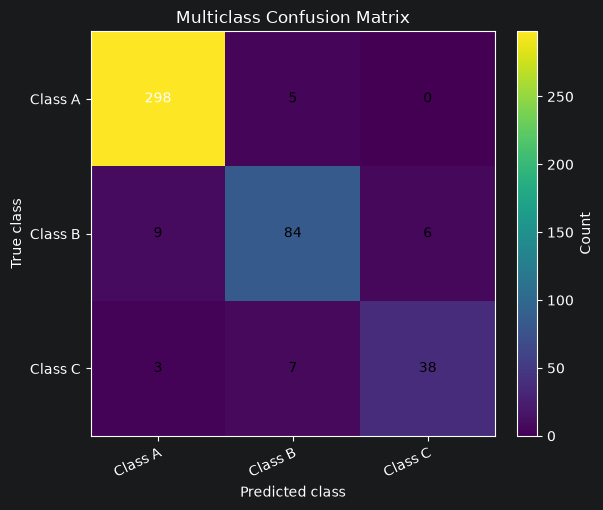

In [26]:
class_ids = np.arange(N_CLASSES)
cm = confusion_matrix(y_test, test_predictions, labels=class_ids)

fig, ax = plt.subplots(figsize=(6.5, 5.2))
image = ax.imshow(cm, interpolation="nearest")
ax.set(
    title="Multiclass Confusion Matrix",
    xlabel="Predicted class",
    ylabel="True class",
    xticks=class_ids,
    yticks=class_ids,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
)
plt.setp(ax.get_xticklabels(), rotation=25, ha="right", rotation_mode="anchor")
threshold = cm.max() / 2 if cm.size else 0
for row in range(N_CLASSES):
    for col in range(N_CLASSES):
        ax.text(col, row, f"{cm[row, col]}", ha="center", va="center",
                color="white" if cm[row, col] > threshold else "black")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Count")
plt.tight_layout()
plt.show()

### 10.2 Row-Normalized Confusion Matrix

Raw counts are affected by class prevalence. Row normalization expresses each cell as a proportion of observations from its true class. The diagonal of the row-normalized matrix corresponds to per-class recall.

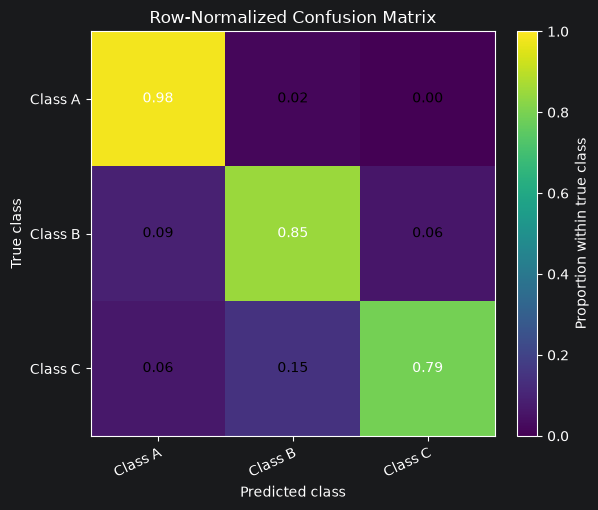

In [27]:
row_totals = cm.sum(axis=1, keepdims=True)
cm_row_normalized = np.divide(cm, row_totals, out=np.zeros_like(cm, dtype=float), where=row_totals != 0)

fig, ax = plt.subplots(figsize=(6.5, 5.2))
image = ax.imshow(cm_row_normalized, vmin=0, vmax=1, interpolation="nearest")
ax.set(
    title="Row-Normalized Confusion Matrix",
    xlabel="Predicted class",
    ylabel="True class",
    xticks=class_ids,
    yticks=class_ids,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
)
plt.setp(ax.get_xticklabels(), rotation=25, ha="right", rotation_mode="anchor")
for row in range(N_CLASSES):
    for col in range(N_CLASSES):
        ax.text(col, row, f"{cm_row_normalized[row, col]:.2f}", ha="center", va="center",
                color="white" if cm_row_normalized[row, col] > 0.5 else "black")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Proportion within true class")
plt.tight_layout()
plt.show()

### 10.3 Per-Class Precision, Recall, F1-Score, and Support

A multiclass report can be understood as a collection of one-vs-rest evaluations. For each class in turn, observations belonging to that class are treated as positive and all other classes are treated as negative.

For class $c$:

$$
\text{Precision}_c = \frac{TP_c}{TP_c + FP_c}
$$

$$
\text{Recall}_c = \frac{TP_c}{TP_c + FN_c}
$$

$$
F1_c = 2\,\frac{\text{Precision}_c\,\text{Recall}_c}{\text{Precision}_c+\text{Recall}_c}
$$

Support is the number of true test observations belonging to that class.

In [28]:
report_dict = classification_report(
    y_test,
    test_predictions,
    labels=class_ids,
    target_names=CLASS_NAMES.tolist(),
    output_dict=True,
    zero_division=0,
)
per_class_report = pd.DataFrame(report_dict).T

display(per_class_report.round(4))

,precision,recall,f1-score,support
Class A,0.9613,0.9835,0.9723,303.0000
Class B,0.8750,0.8485,0.8615,99.0000
Class C,0.8636,0.7917,0.8261,48.0000
accuracy,0.9333,0.9333,0.9333,0.9333
macro avg,0.9000,0.8745,0.8866,450.0000
weighted avg,0.9319,0.9333,0.9323,450.0000


## 11. Micro, Macro, and Weighted Averaging

When a metric is calculated separately for each class, an averaging rule is needed to produce one summary value.

### 11.1 Macro Average

Macro averaging computes the metric independently for every class and then takes the unweighted mean:

$$
M_{\mathrm{macro}} = \frac{1}{C}\sum_{c=1}^{C} M_c
$$

Each class has equal influence, regardless of how many observations it contains.

### 11.2 Weighted Average

Weighted averaging uses each class's support as its weight:

$$
M_{\mathrm{weighted}} = \sum_{c=1}^{C}\frac{n_c}{N}M_c
$$

Classes with more observations have greater influence. Weighted metrics can therefore remain relatively high when performance on a minority class is poor.

### 11.3 Micro Average

Micro averaging aggregates the class-wise true positives, false positives, and false negatives before calculating the metric. In ordinary single-label multiclass classification, each observation has exactly one true label and one predicted label. Consequently, micro-precision, micro-recall, micro-F1, and accuracy are equal.

In [29]:
averaging_results = pd.DataFrame({
    "averaging": ["micro", "macro", "weighted"],
    "precision": [
        precision_score(y_test, test_predictions, average="micro", zero_division=0),
        precision_score(y_test, test_predictions, average="macro", zero_division=0),
        precision_score(y_test, test_predictions, average="weighted", zero_division=0),
    ],
    "recall": [
        recall_score(y_test, test_predictions, average="micro", zero_division=0),
        recall_score(y_test, test_predictions, average="macro", zero_division=0),
        recall_score(y_test, test_predictions, average="weighted", zero_division=0),
    ],
    "f1": [
        f1_score(y_test, test_predictions, average="micro", zero_division=0),
        f1_score(y_test, test_predictions, average="macro", zero_division=0),
        f1_score(y_test, test_predictions, average="weighted", zero_division=0),
    ],
})

display(averaging_results.round(4))
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, test_predictions), 4))

,averaging,precision,recall,f1
0,micro,0.9333,0.9333,0.9333
1,macro,0.9000,0.8745,0.8866
2,weighted,0.9319,0.9333,0.9323


Accuracy: 0.9333
Balanced accuracy: 0.8745


### 11.4 When Should Each Average Be Reported?

| Average | Main interpretation | Useful when |
|---|---|---|
| Micro | Global performance over all decisions | Overall instance-level performance is the priority |
| Macro | Equal contribution from each class | All classes matter, including rare classes |
| Weighted | Contribution proportional to class support | A prevalence-weighted summary is useful |

For imbalanced multiclass problems, reporting only accuracy or weighted-F1 can hide weak minority-class performance. A transparent report should normally include per-class metrics and at least one class-balanced summary such as macro-F1 or balanced accuracy.

## 12. Multiclass ROC and Precision–Recall Analysis

### 12.1 One-vs-Rest Evaluation

ROC-AUC can be extended to multiclass classification using a one-vs-rest (OvR) strategy. For each class, that class is treated as positive and all remaining classes form the negative group. A separate ROC-AUC is calculated from the probability assigned to that class.

The macro OvR ROC-AUC is the unweighted mean of the class-wise OvR AUC values. The weighted OvR ROC-AUC weights each class by its support. The interpretation of OvR AUC can be affected by the composition of each rest group, especially when class proportions are uneven.

In [30]:
# Calculate one-vs-rest ROC-AUC values from the class probability columns.
per_class_roc_auc = {}
for class_id, class_name in enumerate(CLASS_NAMES):
    binary_truth = (y_test == class_id).astype(int)
    per_class_roc_auc[class_name] = roc_auc_score(binary_truth, test_probabilities[:, class_id])

macro_ovr_auc = roc_auc_score(
    y_test, test_probabilities, multi_class="ovr", average="macro", labels=class_ids
)
weighted_ovr_auc = roc_auc_score(
    y_test, test_probabilities, multi_class="ovr", average="weighted", labels=class_ids
)
macro_ovo_auc = roc_auc_score(
    y_test, test_probabilities, multi_class="ovo", average="macro", labels=class_ids
)

print("Per-class OvR ROC-AUC:")
for name, value in per_class_roc_auc.items():
    print(f"  {name}: {value:.4f}")
print(f"\nMacro OvR ROC-AUC:    {macro_ovr_auc:.4f}")
print(f"Weighted OvR ROC-AUC: {weighted_ovr_auc:.4f}")
print(f"Macro OvO ROC-AUC:    {macro_ovo_auc:.4f}")

Per-class OvR ROC-AUC:
  Class A: 0.9728
  Class B: 0.9551
  Class C: 0.9279

Macro OvR ROC-AUC:    0.9519
Weighted OvR ROC-AUC: 0.9641
Macro OvO ROC-AUC:    0.9405


### 12.2 Plot One-vs-Rest ROC Curves

Each curve compares the true-positive rate with the false-positive rate as the score threshold changes for one class versus all other classes. These curves use continuous probability scores, not the final `argmax` class predictions.

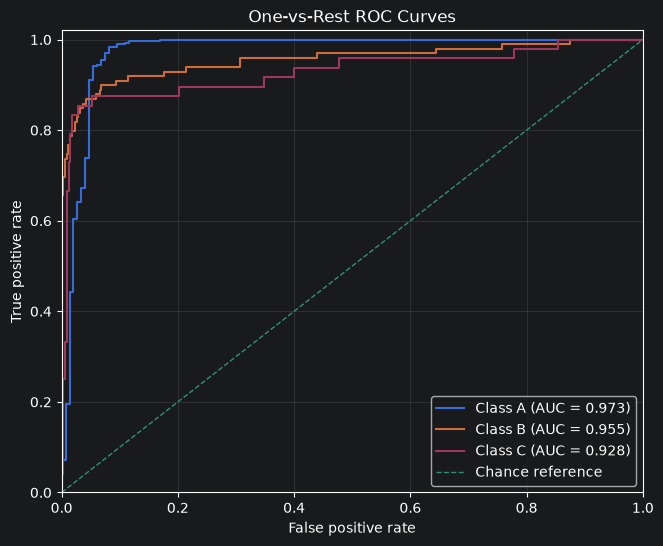

In [31]:
fig, ax = plt.subplots(figsize=(7.5, 6))
for class_id, class_name in enumerate(CLASS_NAMES):
    binary_truth = (y_test == class_id).astype(int)
    fpr, tpr, _ = roc_curve(binary_truth, test_probabilities[:, class_id])
    class_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{class_name} (AUC = {class_auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Chance reference")
ax.set(title="One-vs-Rest ROC Curves", xlabel="False positive rate", ylabel="True positive rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
ax.grid(alpha=0.2)
plt.show()

### 12.3 Precision–Recall Curves and Average Precision

For each class, a one-vs-rest precision–recall curve plots precision against recall as the probability threshold varies. Average precision (AP) summarizes the precision–recall ranking using a weighted sum over recall increments.

The prevalence of the positive class provides a useful horizontal reference: the expected precision of a non-informative ranking is related to the class prevalence. AP values should be interpreted alongside this baseline and the per-class support.

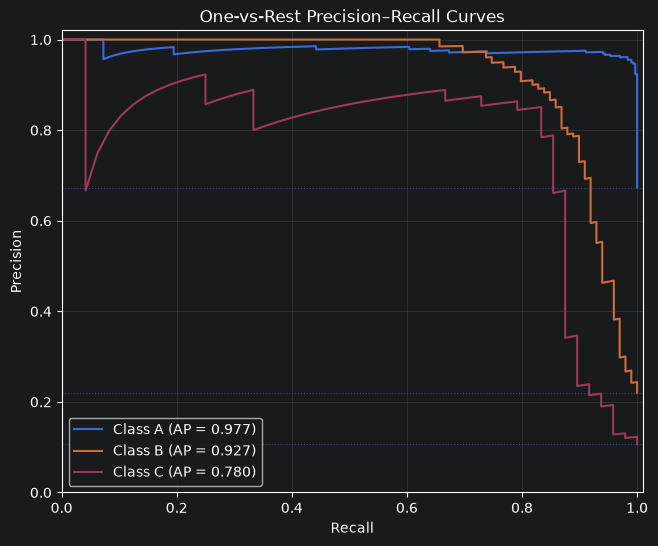

Per-class average precision:
  Class A: 0.9773
  Class B: 0.9274
  Class C: 0.7804
Macro average precision: 0.8950


In [32]:
per_class_ap = {}
fig, ax = plt.subplots(figsize=(7.5, 6))

for class_id, class_name in enumerate(CLASS_NAMES):
    binary_truth = (y_test == class_id).astype(int)
    precision_curve, recall_curve, _ = precision_recall_curve(binary_truth, test_probabilities[:, class_id])
    class_ap = average_precision_score(binary_truth, test_probabilities[:, class_id])
    prevalence = binary_truth.mean()
    per_class_ap[class_name] = class_ap
    ax.plot(recall_curve, precision_curve, label=f"{class_name} (AP = {class_ap:.3f})")
    ax.axhline(prevalence, linestyle=":", linewidth=0.8, alpha=0.6)

ax.set(title="One-vs-Rest Precision–Recall Curves", xlabel="Recall", ylabel="Precision")
ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower left")
ax.grid(alpha=0.2)
plt.show()

macro_average_precision = float(np.mean(list(per_class_ap.values())))
print("Per-class average precision:")
for name, value in per_class_ap.items():
    print(f"  {name}: {value:.4f}")
print(f"Macro average precision: {macro_average_precision:.4f}")

### 12.4 ROC-AUC and Average Precision Are Not Accuracy

- Accuracy evaluates the final class decisions produced by `argmax`.
- ROC-AUC evaluates ranking quality for positive-versus-rest comparisons across score thresholds.
- Average precision summarizes a one-vs-rest precision–recall curve.

A model can have strong ranking metrics but make suboptimal `argmax` decisions for a particular operational objective. Conversely, a metric computed from one selected set of class predictions does not describe the full ranking of probability scores.

## 13. Compare Models and Investigate Errors

### 13.1 Test-Set Comparison

The test set is now used to compare the selected MLP with the two baselines. This comparison is descriptive and does not trigger another model-selection step.

In [33]:
def probability_metrics(y_true, probabilities):
    predictions = np.argmax(probabilities, axis=1)
    return {
        "accuracy": accuracy_score(y_true, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "macro_f1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, predictions, average="weighted", zero_division=0),
        "macro_ovr_auc": roc_auc_score(
            y_true, probabilities, multi_class="ovr", average="macro", labels=class_ids
        ),
        "macro_average_precision": np.mean([
            average_precision_score((y_true == class_id).astype(int), probabilities[:, class_id])
            for class_id in class_ids
        ]),
    }


dummy_test_probabilities = dummy_model.predict_proba(X_test_scaled)
logistic_test_probabilities = logistic_model.predict_proba(X_test_scaled)

comparison_rows = []
for model_name, probabilities in [
    ("Majority-class dummy", dummy_test_probabilities),
    ("Balanced multinomial logistic regression", logistic_test_probabilities),
    (selected_model_name, test_probabilities),
]:
    row = {"model": model_name}
    row.update(probability_metrics(y_test, probabilities))
    comparison_rows.append(row)

model_comparison = pd.DataFrame(comparison_rows).set_index("model")
display(model_comparison.round(4))

,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_ovr_auc,macro_average_precision
model,,,,,,
Majority-class dummy,0.6733,0.3333,0.2683,0.5419,0.5000,0.3333
Balanced multinomial logistic regression,0.7000,0.6718,0.6151,0.7201,0.8371,0.6727
Unweighted MLP,0.9333,0.8745,0.8866,0.9323,0.9519,0.8950


### 13.2 Inspect the Most Confident Errors

A confusion matrix identifies the types of errors but does not show the individual observations. The next cell extracts misclassified test observations and sorts them by the model's highest class probability. These are examples where the model made a confident incorrect prediction.

The feature values are not interpreted as clinical measurements; they are synthetic variables generated for this notebook.

In [34]:
misclassified_mask = test_predictions != y_test
misclassified_indices = np.flatnonzero(misclassified_mask)

if len(misclassified_indices) == 0:
    print("No test observations were misclassified by the selected model.")
else:
    confidence = np.max(test_probabilities[misclassified_indices], axis=1)
    order = np.argsort(confidence)[::-1]
    selected_error_indices = misclassified_indices[order[:15]]

    error_table = pd.DataFrame({
        "test_row": selected_error_indices,
        "true_class": CLASS_NAMES[y_test[selected_error_indices]],
        "predicted_class": CLASS_NAMES[test_predictions[selected_error_indices]],
        "predicted_probability": np.max(test_probabilities[selected_error_indices], axis=1),
        "probability_margin": (
            np.sort(test_probabilities[selected_error_indices], axis=1)[:, -1]
            - np.sort(test_probabilities[selected_error_indices], axis=1)[:, -2]
        ),
    })
    display(error_table.round(4))

print(f"Total test errors: {len(misclassified_indices)} out of {len(y_test)}")

,test_row,true_class,predicted_class,predicted_probability,probability_margin
0,71,Class C,Class A,0.9999,0.9999
1,238,Class B,Class C,0.9997,0.9994
2,3,Class C,Class A,0.9996,0.9992
3,163,Class B,Class A,0.9972,0.9944
4,171,Class C,Class A,0.9911,0.9851
5,182,Class B,Class A,0.9877,0.9755
6,377,Class B,Class A,0.9851,0.9736
7,352,Class B,Class C,0.9839,0.9715
8,186,Class B,Class A,0.9750,0.9508
9,135,Class B,Class C,0.9656,0.9313


Total test errors: 30 out of 450


### 13.3 Inspect the Distribution of Maximum Probabilities

The maximum class probability is the largest value in each softmax output. Comparing this value for correct and incorrect predictions can help identify whether mistakes are often associated with high model confidence. This is a descriptive diagnostic, not a formal calibration assessment.

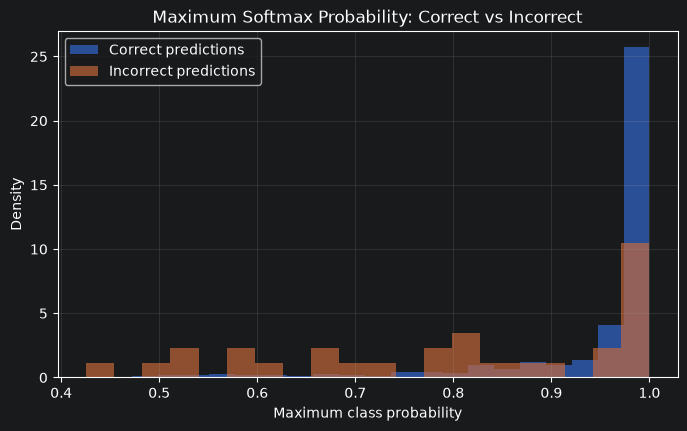

In [35]:
max_probability = np.max(test_probabilities, axis=1)
correct_mask = test_predictions == y_test

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(max_probability[correct_mask], bins=20, alpha=0.65, density=True, label="Correct predictions")
ax.hist(max_probability[~correct_mask], bins=20, alpha=0.65, density=True, label="Incorrect predictions")
ax.set(title="Maximum Softmax Probability: Correct vs Incorrect", xlabel="Maximum class probability", ylabel="Density")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

### 13.4 Class-Imbalance Strategies

Possible strategies include:

- **Class weighting:** increase the loss contribution of under-represented classes.
- **Sample weighting:** assign weights to individual training observations.
- **Resampling:** oversample minority classes or undersample majority classes within the training set only.
- **Data collection:** obtain more representative observations for under-represented classes when possible.
- **Metric selection:** report per-class and macro metrics in addition to overall accuracy.

These strategies are not interchangeable. Class weighting and resampling alter the training process. Neither automatically guarantees better performance or calibrated probabilities. The validation set should be used to compare approaches, while the test set should retain the intended evaluation distribution.

## 14. Common Pitfalls

1. **Using sigmoid for mutually exclusive classes:** a softmax output is usually appropriate when exactly one class is correct.
2. **Using the wrong loss:** integer labels require sparse categorical cross-entropy; one-hot labels require categorical cross-entropy.
3. **Mismatching `from_logits`:** set it according to whether the model returns raw logits or softmax probabilities.
4. **Assuming class IDs are ordinal:** integer labels are identifiers, not numerical measurements.
5. **Reporting accuracy alone:** this can conceal poor recognition of minority classes.
6. **Ignoring per-class support:** a metric without support can be difficult to interpret.
7. **Confusing macro and weighted averages:** they answer different questions about class contribution.
8. **Using hard labels for ROC-AUC or average precision:** probability scores or other continuous decision scores are needed.
9. **Fitting preprocessing on all observations:** fit transformations using training data only.
10. **Calculating class weights using validation or test labels:** calculate them using training labels only.
11. **Selecting models on the test set:** model and strategy selection belong on validation data.
12. **Assuming softmax probabilities are calibrated:** calibration requires separate assessment.
13. **Treating synthetic performance as real-world evidence:** generated data do not establish external validity.

## Key Takeaways

- Single-label multiclass classification assigns exactly one of $C$ classes to each observation.
- Softmax transforms $C$ logits into a probability distribution across classes.
- Integer targets are paired with sparse categorical cross-entropy; one-hot targets are paired with categorical cross-entropy.
- The final Dense layer normally contains one output unit per class.
- Stratified splitting helps preserve class proportions, while preprocessing must be fitted on training data only.
- A confusion matrix and per-class metrics show which classes are being confused.
- Macro averaging gives each class equal influence; weighted averaging reflects class support; micro averaging aggregates decisions globally.
- In ordinary single-label multiclass classification, micro-F1 equals accuracy.
- Multiclass ROC-AUC and average precision are commonly computed using one-vs-rest class scores.
- Class weighting can change minority-class performance, but its usefulness must be checked on validation data.
- The test set is reserved for final evaluation after model selection is complete.

## Exercises

### Exercise 1 — Softmax

1. Calculate the softmax probabilities for logits $[1.5, 0.5, -0.5]$.
2. Explain why subtracting the maximum logit before exponentiation does not change the softmax result.
3. Explain why softmax output does not automatically guarantee calibrated probabilities.

### Exercise 2 — Sparse and One-Hot Targets

For three classes, encode the class sequence `[2, 0, 1, 2]` as one-hot vectors. Explain which Keras loss function should be used for integer labels and which should be used for one-hot labels.

### Exercise 3 — Categorical Cross-Entropy

The true class is class 1 and the predicted probability vector is `[0.15, 0.70, 0.15]`.

1. Calculate the categorical cross-entropy for this observation.
2. Repeat the calculation for `[0.45, 0.10, 0.45]`.
3. Explain why the second prediction receives a larger loss.

### Exercise 4 — Averaging Metrics

Consider three classes with per-class F1-scores of `0.90`, `0.60`, and `0.30`, and supports of `100`, `30`, and `10`.

1. Calculate macro-F1.
2. Calculate weighted-F1.
3. Explain why the values differ and which one is more sensitive to the minority class.

### Exercise 5 — Confusion Matrix

Use the confusion matrix below, with rows as true classes and columns as predicted classes:

$$
\begin{bmatrix}
45 & 4 & 1 \\
8 & 20 & 2 \\
5 & 3 & 7
\end{bmatrix}
$$

1. Calculate recall for each class.
2. Calculate the macro recall (balanced accuracy).
3. Identify the most frequent class confusion.

### Exercise 6 — Class Weighting

1. Train a model without class weights and compare its validation macro-F1 with the class-weighted model.
2. Compare per-class precision and recall.
3. Explain why an improvement in minority-class recall may come with a decrease in precision or overall accuracy.

### Exercise 7 — Model Evaluation

1. Compare macro OvR ROC-AUC and macro average precision.
2. Explain why ROC-AUC and average precision are calculated from probabilities rather than `argmax` labels.
3. Identify one limitation of evaluating with a single synthetic dataset.

### Exercise 8 — Extension

Replace the synthetic dataset with the Iris dataset. Preserve the train/validation/test separation, retrain the MLP, and compare results. Explain how the balanced class distribution changes the interpretation of accuracy and macro-F1.

## Further Reading and References

1. TensorFlow — [Basic classification: Classify images of clothing](https://www.tensorflow.org/tutorials/keras/classification/). See the classification workflow and model evaluation concepts.
2. Keras — [Probabilistic losses](https://keras.io/api/losses/probabilistic_losses/). See `CategoricalCrossentropy` and `SparseCategoricalCrossentropy`.
3. Keras — [Probabilistic metrics](https://keras.io/api/metrics/probabilistic_metrics/). See categorical cross-entropy metrics and probability-based evaluation.
4. scikit-learn — [Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html). See per-class, micro, macro, and weighted metrics.
5. scikit-learn — [Confusion matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).
6. scikit-learn — [ROC-AUC score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html). See multiclass one-vs-rest and one-vs-one strategies.
7. scikit-learn — [Precision, recall, and F-score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html).
8. scikit-learn — [Average precision score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
9. scikit-learn — [Class weights](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html).

**Next notebook:** Notebook 07 — Optimization, Regularization, and Custom Training.